# Machine Learning #07 — Word Embeddings & Text Generation 🔤✨

Today we leave tabular data behind and step into **Natural Language Processing (NLP)**.
We will do two things, both in [PyTorch](https://pytorch.org/):

1. 🧠 **Learn what a *word embedding* is** — a dense, learnable vector that represents a word — and **train our own Word2Vec (Skip-Gram)** model on the *Harry Potter* book.
2. ✍️ **Generate new text** with a **character-level recurrent neural network (LSTM)**.

> ⚠️ **Remember to set a GPU runtime in Colab!** (`Runtime → Change runtime type → GPU`)

## Imports and setup ⚙️

In [1]:
import io
import re
import string
import urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_distances
from scipy.spatial.distance import cosine

sns.set_theme(style="whitegrid")

SEED = 13
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

torch version: 2.6.0+cu124
device: cuda


A tiny helper to plot the training history (a dictionary of `name → list of values`).

In [2]:
def show_history(history):
    plt.figure()
    for key, values in history.items():
        plt.plot(values, label=key)
        
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 🔤 What is a word embedding?

A neural network cannot read text — it needs **numbers**. The simplest idea is to give each word an integer ID (`the → 2`, `road → 3`, …). But raw IDs are meaningless: `3` is not "one more than" `2` in any useful sense, and there is no notion of two words being *similar*.

A **word embedding** solves this. It maps every word to a **dense vector** of real numbers (e.g. 50 numbers), living in a continuous space where:

- 📌 **similar words are close together** (small distance),
- 📌 **relationships become directions** (the step from *man* to *woman* is similar to the step from *king* to *queen*).

In PyTorch, an embedding is just a **trainable lookup table** — the layer **`nn.Embedding(num_words, dim)`**. Row `i` of its weight matrix is the vector for word `i`, and those rows are **learned by gradient descent** like any other parameter.

- Why use it? Dense vectors are compact and capture **meaning**, not just identity.
- Do we have to train our own? Not always — we can reuse **pre-trained** embeddings (we will try both today).
- Any use beyond neural nets? Yes — similarity search, clustering, recommendation, analogies…

## 📒 Word2Vec

**Word2Vec** is a classic, elegant way to *learn* word embeddings. There are two flavours:

- **CBOW (Continuous Bag-of-Words)** — predicts the **middle word** from its surrounding context. Word order in the context is ignored (hence "bag of words").
- **Skip-Gram** — the mirror image: given **one word**, predict the **words around it**.
  - 👉 **We use Skip-Gram** — it is the easier concept to grasp.

![skip-gram](https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/images/dl_07_skip.png?raw=true)

The model is trained on **skip-grams**: pairs `(target_word, context_word)` where `context_word` appears near `target_word` in the text.

| | CBOW | Skip-Gram |
|---|---|---|
| Input | context words | one target word |
| Output | the middle word | the context words |
| Good at | frequent words | rare words, small data |

## 🔎 How is Word2Vec different from GPT-like models?

- **The core idea is shared:** both need to represent words as **dense vectors** in a continuous space.
- **But the purpose differs:**
    - GPT-like models are **generative** — they map a sequence to a new sequence (answering, translation, completion).
    - Classic embeddings feed **vector-to-scalar** tasks — e.g. classification / sentiment analysis.
- **Context handling:**
    - Word2Vec gives each word **one fixed vector** based on co-occurrence statistics. It does *not* adapt to the sentence (the word *"crown"* gets the same vector whether it means money or a king's crown). Upside: it trains on **relatively little data**.
    - GPT models are **contextual** — every token's representation depends on the whole preceding text, capturing nuance and long-range dependencies. Downside: they need **huge** datasets.
- 📌 A "crossover" is **BERT** (a Transformer). It trains with a **masked language model** objective (hide random words, predict them from context) plus **next-sentence prediction** to learn sentence-level relationships.

## We will demonstrate Word2Vec on a single sentence

The context words of each word are defined by a **window size** — how many words to the left and right of the target we look at.

![window table](https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/images/dl_07_tab.png?raw=true)

- The **target word** (input) sits in the middle of the window.
- The **context words** inside the window are what we want the model to predict.
- Near the sentence edges the window is simply cut off.

### Step 1 — tokenize the sentence

In [3]:
# A single demo sentence. We lowercase it and split it into word tokens.
sentence = "The wide road shimmered in the hot sun"
tokens = list(sentence.lower().split())
print(len(tokens))
print(tokens)

8
['the', 'wide', 'road', 'shimmered', 'in', 'the', 'hot', 'sun']


### Step 2 — build the vocabulary (WORD → ID)

We reserve **ID `0` for a special `<pad>` token** (used later to pad short sentences) and number real words from `1`.

In [ ]:
# Build a WORD -> ID dictionary
vocab, index = {}, 1
vocab["<pad>"] = 0
for token in tokens:
    if token not in vocab:
        vocab[token] = index
        index += 1
vocab_size = len(vocab)

print(vocab)

{'<pad>': 0, 'the': 1, 'wide': 2, 'road': 3, 'shimmered': 4, 'in': 5, 'hot': 6, 'sun': 7}


### Step 3 — the inverse mapping (ID → WORD)

Handy for turning model outputs back into readable words.

In [5]:
# Inverse dictionary: ID -> WORD
inverse_vocab = {i: token for token, i in vocab.items()}
print(inverse_vocab)

{0: '<pad>', 1: 'the', 2: 'wide', 3: 'road', 4: 'shimmered', 5: 'in', 6: 'hot', 7: 'sun'}


### Step 4 — the integer-encoded sentence

This is the numeric form the model actually consumes.

In [6]:
# Convert the sentence into a sequence of IDs using our vocabulary.
example_sequence = [vocab[word] for word in tokens]
print(example_sequence)

[1, 2, 3, 4, 5, 1, 6, 7]


## 📌 Generating skip-gram pairs

A skip-gram pair is `(target, context)` where `context` lies within `window_size` words of `target`.
In PyTorch there is no built-in helper for this, so **we write it ourselves** — it is only a few lines, and seeing the mechanics is the whole point.

In [7]:
def generate_skipgrams(sequence, window_size):
    # Return all positive (target, context) pairs from an integer sequence.
    pairs = []
    for i, target in enumerate(sequence):
        # look at a window of `window_size` words to each side
        start = max(0, i - window_size)
        end = min(len(sequence), i + window_size + 1)
        for j in range(start, end):
            if j != i:                       # a word is not its own context
                pairs.append((target, sequence[j]))
    return pairs

window_size = 2   # 2 words to the left and 2 to the right
positive_skip_grams = generate_skipgrams(example_sequence, window_size)
print("number of positive pairs:", len(positive_skip_grams))

number of positive pairs: 26


In [8]:
positive_skip_grams

[(1, 2),
 (1, 3),
 (2, 1),
 (2, 3),
 (2, 4),
 (3, 1),
 (3, 2),
 (3, 4),
 (3, 5),
 (4, 2),
 (4, 3),
 (4, 5),
 (4, 1),
 (5, 3),
 (5, 4),
 (5, 1),
 (5, 6),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (6, 5),
 (6, 1),
 (6, 7),
 (7, 1),
 (7, 6)]

## ⚡ Let's look at a few skip-gram examples

In [9]:
# Show the first 5 pairs both as IDs and as words.
for target, context in positive_skip_grams[:5]:
    print(f"({target}, {context}): ({inverse_vocab[target]}, {inverse_vocab[context]})")

(1, 2): (the, wide)
(1, 3): (the, road)
(2, 1): (wide, the)
(2, 3): (wide, road)
(2, 4): (wide, shimmered)


## 📒 Negative sampling for one skip-gram

The pairs above are all **positive** — words that really co-occur. But training on positives alone is not enough:

⚖️ **Why do we need negatives?** If the network only ever sees correct pairs, it learns the lazy shortcut *"every pair belongs together"* and learns nothing useful. To learn **meaning**, it must also see **negative** pairs — a target word paired with **random** words that do **not** appear in its context. The model then learns by **contrast**: *this belongs (1)* vs *this does not (0)*.

🎲 **How do we generate them?** Take the target word and pair it with a few **random** words drawn from the vocabulary. Most random words simply do not occur next to the target, so they make good negatives. A common trick is to sample proportionally to a word's frequency raised to the power `0.75` (the classic Word2Vec choice), which gently favours less common words.

In [10]:
# Negative sampling for a SINGLE positive pair.
# We draw `num_ns` random words from the vocabulary as negatives,
# making sure the true context word is not accidentally chosen.
target_word, context_word = positive_skip_grams[0]
num_ns = 4   # number of negative samples per positive pair

rng = np.random.default_rng(SEED)

def sample_negatives(true_context, num_ns, vocab_size, rng):
    negatives = []
    while len(negatives) < num_ns:
        cand = int(rng.integers(1, vocab_size))   # skip 0 (<pad>)
        if cand != true_context and cand not in negatives:
            negatives.append(cand)
    return negatives

negative_samples = sample_negatives(context_word, num_ns, vocab_size, rng)
print("target :", inverse_vocab[target_word])
print("context:", inverse_vocab[context_word])
print("negatives:", [inverse_vocab[n] for n in negative_samples])

target : the
context: wide
negatives: ['sun', 'hot', 'the', 'in']


Now we assemble **one training example**: the context vector is the true context followed by the negatives, and the label is `1` for the true context and `0` for each negative.

In [11]:
# Build the context vector and its labels for one training example.
context = [context_word] + negative_samples   # [positive, neg, neg, neg, neg]
label = [1] + [0] * num_ns                    # [1, 0, 0, 0, 0]
target = target_word

In [12]:
print(f"target_index    : {target}")
print(f"target_word     : {inverse_vocab[target]}")
print(f"context_indices : {context}")
print(f"context_words   : {[inverse_vocab[c] for c in context]}")
print(f"label           : {label}")

target_index    : 1
target_word     : the
context_indices : [2, 7, 6, 1, 5]
context_words   : ['wide', 'sun', 'hot', 'the', 'in']
label           : [1, 0, 0, 0, 0]


## Subsampling of frequent words 🗑️

Real corpora are flooded with **stopwords** (*the*, *is*, *on*, *a*). These are everywhere and carry almost no meaning, so pairs like *(road, the)* barely help. To improve quality we **subsample**: while sliding the window, we sometimes **skip** very frequent words on purpose.

📊 A **sampling table** controls this. `sampling_table[i]` is the probability of **keeping** the `i`-th most frequent word:

- rare, specific words (e.g. *shimmered*) → probability ≈ **1.0** (almost always kept),
- extremely frequent words (e.g. *the*) → **low** probability (often skipped).

A standard formula for the *discard* probability of a word with frequency $f$ is

$$P_\text{discard}(w) = 1 - \sqrt{\frac{t}{f(w)}}$$

where $t$ is a small threshold (e.g. $10^{-5}$). The example below shows the *keep* probability for a few made-up frequencies.

In [13]:
# Illustrate subsampling: keep-probability for words of decreasing frequency.
# Frequencies here are fractions of the corpus (most frequent word first).
t = 1e-3
freqs = np.array([0.20, 0.10, 0.05, 0.02, 0.01, 0.005, 0.001, 0.0005])
keep_prob = np.minimum(1.0, np.sqrt(t / freqs))   # closer to 1 for rare words
for f, p in zip(freqs, keep_prob):
    print(f"freq={f:<8} keep_prob={p:.3f}")

freq=0.2      keep_prob=0.071
freq=0.1      keep_prob=0.100
freq=0.05     keep_prob=0.141
freq=0.02     keep_prob=0.224
freq=0.01     keep_prob=0.316
freq=0.005    keep_prob=0.447
freq=0.001    keep_prob=1.000
freq=0.0005   keep_prob=1.000


## ⚡ Putting it all together

We wrap the whole pipeline into one function that, given a list of integer sequences, returns three arrays:

- `targets`  — the target word IDs,
- `contexts` — for each target, `[positive, neg_1, …, neg_num_ns]`,
- `labels`   — the matching `[1, 0, …, 0]` rows.

For speed we pre-build a **negative-sampling table**: a big array where each word appears proportionally to `frequency**0.75`. Drawing a random index from it gives a frequency-aware negative sample instantly.

In [14]:
def build_neg_table(sequences, vocab_size, table_size=1_000_000, power=0.75):
    # Count word frequencies, raise to `power`, and fill a lookup table
    # where each word ID appears proportionally to its (smoothed) frequency.
    counts = np.zeros(vocab_size)
    for seq in sequences:
        for w in seq:
            counts[w] += 1
    counts[0] = 0                      # never sample <pad>
    weights = counts ** power
    probs = weights / weights.sum()
    table = np.random.choice(vocab_size, size=table_size, p=probs)
    return table


def generate_training_data(sequences, window_size, num_ns, vocab_size, neg_table, seed=SEED):
    rng = np.random.default_rng(seed)
    targets, contexts, labels = [], [], []
    table_size = len(neg_table)

    for sequence in sequences:
        # drop padding (0) so it never becomes a target/context
        seq = [w for w in sequence if w != 0]
        for target_word, context_word in generate_skipgrams(seq, window_size):
            # draw num_ns negatives from the frequency table, avoiding the true context
            negatives = []
            while len(negatives) < num_ns:
                cand = int(neg_table[rng.integers(0, table_size)])
                if cand != context_word and cand != 0:
                    negatives.append(cand)
            targets.append(target_word)
            contexts.append([context_word] + negatives)
            labels.append([1] + [0] * num_ns)

    return np.array(targets), np.array(contexts), np.array(labels)

## 📚 Download the *Harry Potter* book and train our own embedding

In [15]:
# Download "Harry Potter and the Sorcerer's Stone" as a plain-text file.
url = "https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/main/datasets/hp1.txt"
path_to_file = "hp1.txt"
urllib.request.urlretrieve(url, path_to_file)
print("downloaded to", path_to_file)

downloaded to hp1.txt


## First 50 lines of the book

In [16]:
with open(path_to_file) as f:
    lines = f.read().splitlines()
for line in lines[:50]:
    print(line)

Harry Potter and the Sorcerer's Stone


CHAPTER ONE

THE BOY WHO LIVED

Mr. and Mrs. Dursley, of number four, Privet Drive, were proud to say
that they were perfectly normal, thank you very much. They were the last
people you'd expect to be involved in anything strange or mysterious,
because they just didn't hold with such nonsense.

Mr. Dursley was the director of a firm called Grunnings, which made
drills. He was a big, beefy man with hardly any neck, although he did
have a very large mustache. Mrs. Dursley was thin and blonde and had
nearly twice the usual amount of neck, which came in very useful as she
spent so much of her time craning over garden fences, spying on the
neighbors. The Dursleys had a small son called Dudley and in their
opinion there was no finer boy anywhere.

The Dursleys had everything they wanted, but they also had a secret, and
their greatest fear was that somebody would discover it. They didn't
think they could bear it if anyone found out about the Potters. Mr

# 🚀 Text preprocessing

We clean the raw text **line by line**:

- skip the **title** line,
- drop **empty** lines and **`CHAPTER …`** headings (not useful),
- convert to **lowercase**,
- **remove punctuation** (using the punctuation set from Python's `string` module).

The goal is clean English text we can split into word tokens.

In [17]:
punct_pattern = f"[{re.escape(string.punctuation)}]"
print("punctuation to remove:", re.escape(string.punctuation))

clean_lines = []
for raw in lines[1:]:                       # skip the title (first line)
    if len(raw.strip()) == 0:               # drop empty lines
        continue
    if raw.startswith("CHAPTER"):           # drop chapter headings
        continue
    text = raw.lower()                      # lowercase
    text = re.sub(punct_pattern, "", text)  # strip punctuation
    clean_lines.append(text)

print("clean lines:", len(clean_lines))

punctuation to remove: !"\#\$%\&'\(\)\*\+,\-\./:;<=>\?@\[\\\]\^_`\{\|\}\~
clean lines: 7628


## Here is our pre-processed dataset (first 10 lines)

In [18]:
for line in clean_lines[:10]:
    print(repr(line))

'the boy who lived'
'mr and mrs dursley of number four privet drive were proud to say'
'that they were perfectly normal thank you very much they were the last'
'people youd expect to be involved in anything strange or mysterious'
'because they just didnt hold with such nonsense'
'mr dursley was the director of a firm called grunnings which made'
'drills he was a big beefy man with hardly any neck although he did'
'have a very large mustache mrs dursley was thin and blonde and had'
'nearly twice the usual amount of neck which came in very useful as she'
'spent so much of her time craning over garden fences spying on the'


## A few corpus statistics

In [19]:
n_lines = len(clean_lines)
total_len = sum(len(line) for line in clean_lines)
avg_len = total_len // n_lines
print("total number of lines :", n_lines)
print("total length (chars)  :", total_len)
print("average line length   :", avg_len)

total number of lines : 7628
total length (chars)  : 405596
average line length   : 53


# 🔢 Integer encoding of the tokens

We build a **vocabulary** ordered by word frequency and turn every line into a fixed-length sequence of IDs. This mirrors what a text-vectorization layer does, but we do it explicitly:

- **Sort words by frequency** — the most frequent word gets the **lowest** ID (after the reserved tokens).
- Reserve `ID 0 = <pad>` (padding) and `ID 1 = <unk>` (unknown / out-of-vocabulary).
- **Pad or truncate** each line to a fixed length.

**Parameters**

- no vocabulary-size limit (keep all words),
- `output_sequence_length = 15` — the average line is ~75 characters ≈ 12–15 words.

In [20]:
sequence_length = 15

# Count word frequencies across the whole corpus.
counter = Counter()
for line in clean_lines:
    counter.update(line.split())

# Vocabulary: index 0 = <pad>, index 1 = <unk>, then words by decreasing frequency.
inverse_vocab = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common()]
vocab = {w: i for i, w in enumerate(inverse_vocab)}
vocab_size = len(vocab)

In [21]:
def vectorize(line, length=sequence_length):
    # Convert a line into a fixed-length list of token IDs (pad/truncate).
    ids = [vocab.get(tok, 1) for tok in line.split()]   # 1 = <unk>
    ids = ids[:length]
    ids = ids + [0] * (length - len(ids))               # 0 = <pad>
    return ids

## Vocabulary example (first 20 tokens, most frequent first)

In [22]:
print(inverse_vocab[:20])

['<pad>', '<unk>', 'the', 'and', 'to', 'a', 'he', 'of', 'harry', 'was', 'it', 'in', 'his', 'you', 'said', 'had', 'i', 'on', 'at', 'that']


## Number of tokens in the vocabulary

In [23]:
print(vocab_size)

6036


### 🔎 Why are there `0` IDs?

Every line is padded to a fixed length of `15`. Lines shorter than 15 words are **padded with zeros**.

- `ID 0` = padding (`<pad>`)
- `ID 1` = unknown word (`<unk>`)
- `ID 2` = the most frequent real word in the text

The padding IDs are removed before we build skip-grams, so they never pollute training.

In [24]:
# Vectorize every line, then show the first 5 sequences as IDs and words.
sequences = [vectorize(line) for line in clean_lines]
for seq in sequences[:5]:
    print(f"{seq} => {[inverse_vocab[i] for i in seq]}")

[2, 141, 74, 1036, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] => ['the', 'boy', 'who', 'lived', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
[145, 3, 255, 219, 7, 607, 359, 630, 515, 32, 1214, 4, 156, 0, 0] => ['mr', 'and', 'mrs', 'dursley', 'of', 'number', 'four', 'privet', 'drive', 'were', 'proud', 'to', 'say', '<pad>', '<pad>']
[19, 20, 32, 1507, 931, 1110, 13, 68, 155, 20, 32, 2, 142, 0, 0] => ['that', 'they', 'were', 'perfectly', 'normal', 'thank', 'you', 'very', 'much', 'they', 'were', 'the', 'last', '<pad>', '<pad>']
[130, 469, 750, 4, 30, 1508, 11, 162, 470, 102, 1356, 0, 0, 0, 0] => ['people', 'youd', 'expect', 'to', 'be', 'involved', 'in', 'anything', 'strange', 'or', 'mysterious', '<pad>', '<pad>', '<pad>', '<pad>']
[139, 20, 61, 56, 804, 24, 493, 1701, 0, 0, 0, 0, 0, 0, 0] => ['because', 'they', 'just', 'didnt', 'hold', 'with', 'such', 'nonsense', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


## 🚀 Build the whole training set

`window_size = 2`, `num_ns = 4` (4 negatives per positive). This can take a little while — it produces hundreds of thousands of training examples.

In [25]:
neg_table = build_neg_table(sequences, vocab_size)

targets, contexts, labels = generate_training_data(
    sequences=sequences,
    window_size=2,
    num_ns=4,
    vocab_size=vocab_size,
    neg_table=neg_table,
    seed=SEED,
)

print("targets.shape :", targets.shape)
print("contexts.shape:", contexts.shape)
print("labels.shape  :", labels.shape)

targets.shape : (264662,)
contexts.shape: (264662, 5)
labels.shape  : (264662, 5)


In [26]:
# A quick peek at the three arrays.
print("targets  :", targets[:3])
print("contexts :\n", contexts[:3])
print("labels   :\n", labels[:3])

targets  : [  2   2 141]
contexts :
 [[ 141  144 1420  239  101]
 [  74 5642   22   22    4]
 [   2 1979   56  838 1697]]
labels   :
 [[1 0 0 0 0]
 [1 0 0 0 0]
 [1 0 0 0 0]]


## 🔥 A PyTorch `Dataset` and `DataLoader`

In PyTorch we feed the model through a **`DataLoader`**, which handles **shuffling** and **batching** for us. We wrap our three arrays in a **`TensorDataset`** first.

- 💡 `num_workers` lets the **CPU prepare the next batch while the GPU trains** on the current one (the producer/consumer overlap that keeps the expensive GPU busy).
- 💡 `pin_memory=True` speeds up the CPU→GPU transfer.

In [27]:
BATCH_SIZE = 1024

targets_t = torch.tensor(targets, dtype=torch.long)
contexts_t = torch.tensor(contexts, dtype=torch.long)
labels_t = torch.tensor(labels, dtype=torch.float32)

w2v_dataset = TensorDataset(targets_t, contexts_t, labels_t)
w2v_loader = DataLoader(
    w2v_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True,
)
print("number of batches per epoch:", len(w2v_loader))

number of batches per epoch: 258


## 🚀 Define and train the Word2Vec model

The Skip-Gram model has **two embedding tables** of the same size:

$$\text{target ID} \xrightarrow{\text{target embedding}} \mathbf{t}\in\mathbb{R}^{d}, \qquad \text{context IDs} \xrightarrow{\text{context embedding}} \mathbf{c}_k\in\mathbb{R}^{d}$$

For each context word we take the **dot product** with the target vector — a similarity score (a *logit*):

$$\text{score}_k = \mathbf{t}\cdot\mathbf{c}_k$$

The true context should score highest. Since the **positive** is always at **index 0** of our context vector, training is just a `(num_ns+1)`-way classification where **class 0 is correct**. After training, the **target embedding table is our set of word vectors**.

In [28]:
class Word2Vec(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        # two separate lookup tables: one for target words, one for context words
        self.target_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.context_embedding = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, target_ids, context_ids):
        t = self.target_embedding(target_ids)        # (B, d)
        c = self.context_embedding(context_ids)      # (B, num_ns+1, d)
        # dot product of target with every context vector -> (B, num_ns+1)
        scores = torch.bmm(c, t.unsqueeze(2)).squeeze(2)
        return scores


embedding_dim = 50
w2v_model = Word2Vec(vocab_size, embedding_dim).to(device)
print(w2v_model)

Word2Vec(
  (target_embedding): Embedding(6036, 50)
  (context_embedding): Embedding(6036, 50)
)


#### Loss function and optimizer ⚖️

The positive context sits at index `0`, so the correct class is always `0`. We use **`CrossEntropyLoss`** (which applies softmax internally over the `num_ns+1` scores) and the **AdamW** optimizer.

In [29]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(w2v_model.parameters())
print("loss     :", criterion)
print("optimizer:", optimizer.__class__.__name__)

loss     : CrossEntropyLoss()
optimizer: AdamW


#### The training loop ⭐

Same rhythm as always: **forward → loss → `zero_grad` → `backward` → `step`**, now looping over the `DataLoader` batches.

In [30]:
n_epochs = 50
history = {"train_loss": []}

for epoch in range(n_epochs):
    w2v_model.train()
    epoch_loss = 0.0
    for target_b, context_b, label_b in w2v_loader:
        target_b = target_b.to(device)
        context_b = context_b.to(device)
        # the positive is always at index 0 -> correct class is 0
        target_class = label_b.argmax(dim=1).to(device)

        scores = w2v_model(target_b, context_b)
        loss = criterion(scores, target_class)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(w2v_loader)
    history["train_loss"].append(epoch_loss)
    if (epoch + 1) % 5 == 0:
        print(f"epoch {epoch+1:3d} | loss {epoch_loss:.4f}")

epoch   5 | loss 4.8156
epoch  10 | loss 2.9562
epoch  15 | loss 2.0603
epoch  20 | loss 1.5961
epoch  25 | loss 1.3372
epoch  30 | loss 1.1811
epoch  35 | loss 1.0770
epoch  40 | loss 1.0008
epoch  45 | loss 0.9409
epoch  50 | loss 0.8922


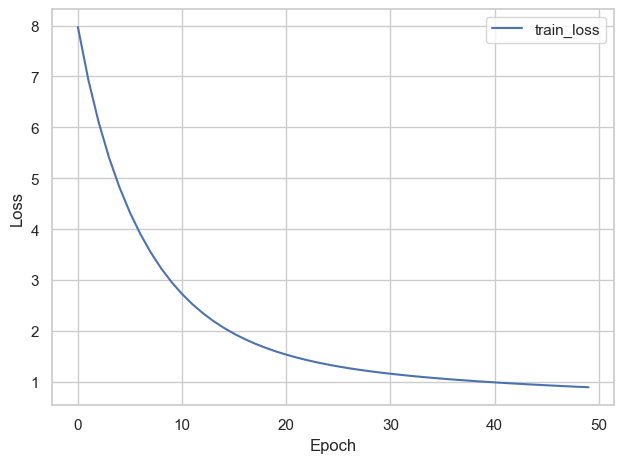

In [31]:
show_history(history)

## ⚡ Extract the learned vectors

The learned word vectors are simply the **weights of the target embedding table** — a matrix of shape `(vocab_size, embedding_dim)`.

In [32]:
# (vocab_size, embedding_dim) matrix of learned word vectors
weights = w2v_model.target_embedding.weight.detach().cpu().numpy()
print("embedding matrix shape:", weights.shape)

embedding matrix shape: (6036, 50)


## 🔎 A quick 2D view with PCA

50 dimensions are impossible to picture, so we project a handful of words down to 2D with **PCA** and plot them.

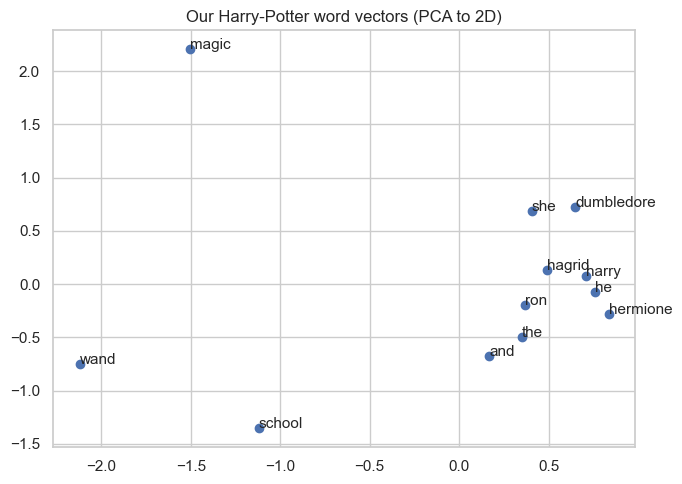

In [ ]:
words_to_plot = ["harry", "ron", "hermione", "hagrid", "dumbledore",
                 "wand", "magic", "school", "the", "and", "he", "she"]
words_to_plot = [w for w in words_to_plot if w in vocab]

idx = [vocab[w] for w in words_to_plot]
pts = PCA(n_components=2, random_state=SEED).fit_transform(weights[idx])

plt.figure(figsize=(7, 5))
plt.scatter(pts[:, 0], pts[:, 1])
for (x, y), w in zip(pts, words_to_plot):
    plt.annotate(w, (x, y), fontsize=11)
plt.title("Our Harry-Potter word vectors (PCA to 2D)")
plt.tight_layout()
plt.show()

# The similar-word search 🙂

The standard way to find related words: compute the **cosine distance** from a query word to every other word, then take the closest few.

In [34]:
id2word = {i: w for i, w in enumerate(inverse_vocab)}
word2id = {w: i for i, w in enumerate(inverse_vocab)}

In [35]:
# Cosine-distance matrix between all word vectors, then nearest neighbours.
distance_matrix = cosine_distances(weights)
print("distance matrix shape:", distance_matrix.shape)

query_words = ["harry", "hagrid", "potter", "go", "he", "the", "one", "hermione"]
similar_words = {
    w: [id2word[i] for i in distance_matrix[word2id[w]].argsort()[1:6]]
    for w in query_words if w in word2id
}
similar_words

distance matrix shape: (6036, 6036)


{'harry': ['hagrid', 'he', 'ron', 'hermione', 'it'],
 'hagrid': ['harry', 'dumbledore', 'laugh', 'it', 'hermione'],
 'potter': ['examine', 'this', 'quidditch', 'whats', 'forge'],
 'go': ['tell', 'we', 'know', 'you', 'pop'],
 'he': ['harry', 'snape', 'who', 'hermione', 'seamus'],
 'the': ['hut', 'back', 'flung', 'laid', 'specimen'],
 'one': ['classes', 'scroll', 'much', 'blond', 'tom'],
 'hermione': ['harry', 'he', 'hagrid', 'who', 'seamus']}

### Why are the results underwhelming? 😪

Our embedding struggles because:

1. **Too little data** — a single book (~7 000 unique words).
2. **Few epochs** — 50 epochs may not be enough to converge.
3. **Small context window** — `window_size=2` sees only tight contexts.
4. **Small dimension** — `embedding_dim=50` may be too small for this vocabulary.

💡 Real embeddings are trained on **billions** of words (Wikipedia, Common Crawl) for many epochs with windows of 5–10.

Let's swap in some **pre-trained** vectors and see the difference.

# 🎁 Pre-trained GloVe vectors

**GloVe** vectors were trained on billions of tokens. We only need the small **50-dimensional** file (`glove.6B.50d.txt`).

In [ ]:
# The full archive is large; we only use the 50d file inside it.
!wget -q http://nlp.stanford.edu/data/glove.6B.zip
!unzip -q -o glove.6B.zip glove.6B.50d.txt

In [36]:
# Load GloVe into a dict: word -> 50-dim numpy vector (~400 000 words).
path_to_glove_file = "glove.6B.50d.txt"
embeddings_index = {}
with open(path_to_glove_file, "r", encoding="utf-8") as f:
    for line in f:
        word, coefs = line.split(maxsplit=1)
        embeddings_index[word] = np.fromstring(coefs, "f", sep=" ")
print("Found %s word vectors." % len(embeddings_index))

Found 400000 word vectors.


## 💡 What a latent vector looks like — `audi` and `bmw`

Each word is 50 numbers. Two car brands should have **similar** vectors.

In [37]:
embeddings_index["audi"]

array([ 0.051355 ,  0.11694  ,  1.0251   ,  0.12414  , -0.83236  ,
        1.0288   , -0.64566  , -1.4468   , -0.89265  , -0.32658  ,
        0.66507  , -0.65524  , -1.8323   , -1.0347   ,  0.13486  ,
       -0.033565 , -0.2208   ,  1.855    , -0.2495   , -0.84343  ,
        0.14318  , -0.81258  , -0.84232  ,  1.1247   , -0.075604 ,
       -0.30852  , -0.79071  ,  0.80721  , -0.24747  , -0.029263 ,
        0.2684   ,  0.6531   ,  0.48872  ,  1.1838   ,  0.5606   ,
       -0.68087  ,  0.25192  ,  0.98091  , -1.0433   , -0.27203  ,
        1.1912   , -0.88594  ,  0.022038 , -0.82012  , -0.0022396,
       -0.68251  ,  0.12713  ,  0.85041  ,  1.002    ,  0.33904  ],
      dtype=float32)

In [38]:
embeddings_index["bmw"]

array([ 0.70038 , -0.16073 ,  1.3423  ,  0.63331 , -0.21958 ,  0.31944 ,
       -0.67042 , -0.94041 , -0.56935 , -0.67842 ,  0.39705 , -0.18964 ,
       -2.2101  , -0.90947 ,  0.95511 , -0.01321 , -0.32738 ,  1.1554  ,
       -0.48464 , -1.7606  , -0.051495, -1.0745  , -1.183   ,  0.68672 ,
       -0.107   , -0.42152 , -0.15516 ,  0.12724 , -0.42114 ,  0.30905 ,
        0.59784 ,  0.050149,  0.24022 ,  0.86494 ,  0.63488 , -0.75644 ,
       -0.09189 ,  1.0218  , -0.96638 , -0.90508 ,  0.80575 , -0.75225 ,
        0.7642  , -0.94425 ,  0.4609  ,  0.11877 ,  0.24907 ,  0.066667,
        0.59622 ,  0.1275  ], dtype=float32)

## 💡 Hypothesis: `audi`–`bmw` should be closer than `audi`–`king`

Cosine distance is small for similar meanings and large for unrelated words.

In [39]:
# Two car brands -> small distance.
cosine(embeddings_index["audi"], embeddings_index["bmw"])

np.float32(0.16636306)

In [40]:
# A car brand vs. a monarch -> much larger distance.
cosine(embeddings_index["audi"], embeddings_index["king"])

np.float32(1.0900573)

## 🚀 Build an embedding matrix for analogies

We stack all GloVe vectors into a matrix of shape `(num_words, 50)` so we can compare a word to **all** others at once (vectorized cosine distance).

In [41]:
embedding_dim = 50
word2id = {w: i for i, w in enumerate(embeddings_index.keys())}
id2word = {i: w for w, i in word2id.items()}

embedding_matrix = np.zeros((len(word2id), embedding_dim))
for word, i in word2id.items():
    embedding_matrix[i] = embeddings_index[word]
print("embedding matrix shape:", embedding_matrix.shape)

embedding matrix shape: (400000, 50)


### 🔥 PyTorch tie-in: load GloVe into an `nn.Embedding`

Pre-trained vectors are not just for NumPy — we can drop them straight into a PyTorch layer with **`nn.Embedding.from_pretrained`** and use it inside any model.

In [42]:
glove_layer = nn.Embedding.from_pretrained(
    torch.tensor(embedding_matrix, dtype=torch.float32), freeze=True
)
# look up the vector for "king" via the PyTorch layer
king_vec = glove_layer(torch.tensor(word2id["king"]))
print("king vector via nn.Embedding, shape:", king_vec.shape)

king vector via nn.Embedding, shape: torch.Size([50])


## Finding the closest words is easy now

In [43]:
# 5 nearest words to "man".
c_w = cosine_distances(embedding_matrix[word2id["man"]].reshape(-1, 50), embedding_matrix)
for x in c_w.argsort().ravel()[1:6]:
    print(id2word[x])

woman
boy
another
old
one


In [44]:
# 5 nearest words to "woman".
c_w = cosine_distances(embedding_matrix[word2id["woman"]].reshape(-1, 50), embedding_matrix)
for x in c_w.argsort().ravel()[1:6]:
    print(id2word[x])

girl
man
mother
her
boy


## 👑 The famous analogy: `man − woman ≈ king − queen`

A hallmark of good embeddings: **relationships are consistent directions**.

$$\text{vec}(\text{king}) - \text{vec}(\text{man}) \approx \text{vec}(\text{queen}) - \text{vec}(\text{woman})$$

Rearranged, this means:

$$\text{vec}(\text{queen}) + \big(\text{vec}(\text{man}) - \text{vec}(\text{woman})\big) \approx \text{vec}(\text{king})$$

The difference `man − woman` roughly encodes the concept of **gender**. Add it to `queen` and we should land near `king`.

In [47]:
# The "gender direction".
dist = embeddings_index["man"] - embeddings_index["woman"]

In [50]:
# queen + (man - woman) should be close to "king".
summed = embeddings_index["queen"] + dist

In [51]:
res = cosine_distances(summed.reshape(-1, 50), embedding_matrix)
print("Closest words to  queen + (man - woman):")
for x in res.argsort().ravel()[1:6]:
    print(id2word[x])

Closest words to  queen + (man - woman):
king
prince
crown
coronation
royal


# And here we go 🙂 — `king` shows up near the top!

That is the payoff: good embeddings capture meaning so well that **arithmetic on vectors matches analogies in language**.

# ✍️ Part 2 — Text generation with a character-level RNN 🙂

Text is a **sequence** — order and context matter. Plain feed-forward networks take a fixed input and have **no memory** of previous steps. A **recurrent network**, and specifically an **LSTM** (Long Short-Term Memory), keeps a **hidden state** across the sequence and can carry context forward.

We can model text at two granularities:

| | Word-level | Character-level |
|---|---|---|
| Token | a word | a single character |
| Vocabulary | tens of thousands | **27** (a–z + space) |
| Data needed | large | smaller |
| Output | cleaner sentences | can invent new words |

With only one book (~400 000 characters) we use a **character-level** model, and we simplify further by keeping only **lowercase letters and spaces**.

- 🔎 If we had a *huge* corpus instead, which level would you prefer, and why?

In [52]:
# Join all cleaned, lowercased lines into one long string.
# (We reuse the lowercased text; here we keep letters and spaces only.)
raw_lowercase = " ".join(line for line in clean_lines)
txt_one_line = raw_lowercase
print(txt_one_line[:150])

the boy who lived mr and mrs dursley of number four privet drive were proud to say that they were perfectly normal thank you very much they were the l


## Keep only lowercase letters and spaces

This shrinks the vocabulary to just a handful of tokens and makes the task tractable on a small corpus. The cost: the model loses digits, capitalisation and punctuation.

In [53]:
# Filter: keep a-z and space, drop everything else.
letters = [ch for ch in txt_one_line if ("a" <= ch <= "z") or ch == " "]
print(letters[:10])

['t', 'h', 'e', ' ', 'b', 'o', 'y', ' ', 'w', 'h']


## How big is our corpus?

In [54]:
print("total characters:", len(letters))

total characters: 413175


### 💡 But only 27 unique tokens

In [55]:
chars = sorted(set(letters))
print("total unique chars:", len(chars))
print(chars)

total unique chars: 27
[' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


## `CHAR → ID` and `ID → CHAR` lookup tables

In [56]:
char_indices = {c: i for i, c in enumerate(chars)}   # CHAR -> ID
indices_char = {i: c for i, c in enumerate(chars)}   # ID -> CHAR
print(char_indices)

{' ': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26}


## ⚡ Fixed-length sequences with a sliding window

For training we need `(X, y)` pairs:

- a window of `SEQ_LEN = 40` characters is the input **X**,
- the **next** character (right after the window) is the target **y**,
- the window slides right by `step` and we repeat.

```
X[0] = "the boy who lived  mr and mrs durs..."   (40 chars)
y[0] = "l"                                        (the 41st char)
X[1] =  "he boy who lived  mr and mrs dursl..."  (shifted by 1)
y[1] = "e"
```

In [57]:
SEQ_LEN = 40   # context length
step = 1       # slide by 1 char (lots of overlapping examples)

X, y = [], []
for i in range(0, len(letters) - SEQ_LEN, step):
    X.append(letters[i:i + SEQ_LEN])   # 40 input characters
    y.append(letters[i + SEQ_LEN])     # the next character (target)
print("number of training sequences:", len(X))

number of training sequences: 413135


## Let's look at an example

💡 Notice how the second sequence is the first one shifted by a single character.

In [58]:
print("".join(X[0]))

the boy who lived mr and mrs dursley of 


In [59]:
print("".join(X[1]))

he boy who lived mr and mrs dursley of n


In [60]:
print("target of X[0]:", repr(y[0]))

target of X[0]: 'n'


### 📌 In PyTorch we skip one-hot encoding

With a word-level model we would normally reach for an **embedding**. With only 27 characters, a common alternative is **one-hot** encoding. But in PyTorch we get something cleaner for *free*:

- 🔥 **`nn.Embedding` takes integer IDs directly** — no need to build one-hot vectors by hand. (This is exactly the lookup table from Part 1, now over characters.)
- 🔥 **`nn.CrossEntropyLoss` takes the integer class as the target** — again no one-hot.

So we keep our data as **plain integer tensors**. Less memory, less code, and it reinforces the embedding idea from the first half.

In [61]:
# Encode inputs and targets as integer tensors (NOT one-hot).
X_ids = torch.tensor([[char_indices[c] for c in seq] for seq in X], dtype=torch.long)
y_ids = torch.tensor([char_indices[c] for c in y], dtype=torch.long)
print("X_ids shape:", X_ids.shape)   # (num_sequences, SEQ_LEN)
print("y_ids shape:", y_ids.shape)   # (num_sequences,)

X_ids shape: torch.Size([413135, 40])
y_ids shape: torch.Size([413135])


In [62]:
# Dataset + DataLoader for the generator.
gen_dataset = TensorDataset(X_ids, y_ids)
gen_loader = DataLoader(
    gen_dataset, batch_size=256, shuffle=True, drop_last=True,
    num_workers=2, pin_memory=True,
)
print("batches per epoch:", len(gen_loader))

batches per epoch: 1613


# 🚀 Model definition and training

Our generator is:

$$\text{char IDs} \rightarrow \boxed{\texttt{nn.Embedding}} \rightarrow \boxed{\texttt{2-layer nn.LSTM}} \rightarrow \text{last hidden state} \rightarrow \boxed{\texttt{Linear}} \rightarrow \text{27 logits}$$

- **`nn.Embedding(27, embed_dim)`** — turns each character ID into a small vector.
- **`nn.LSTM(embed_dim, hidden, num_layers=2)`** — reads the sequence and keeps a hidden state. The first layer captures low-level patterns (letter transitions); the second captures longer dependencies (word/phrase structure).
- We take the **last time-step's** hidden state, apply **dropout**, and a **`Linear`** layer produces one **logit per character**.

**Loss:** `CrossEntropyLoss` — a 27-way classification of *which character comes next*.

In [63]:
class CharRNN(nn.Module):
    def __init__(self, n_chars, embed_dim=32, hidden_dim=128, num_layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(n_chars, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, n_chars)

    def forward(self, x):
        x = self.embedding(x)          # (B, SEQ_LEN) -> (B, SEQ_LEN, embed_dim)
        out, _ = self.lstm(x)          # (B, SEQ_LEN, hidden_dim)
        last = out[:, -1, :]           # keep the final time-step -> (B, hidden_dim)
        last = self.dropout(last)
        return self.fc(last)           # (B, n_chars) logits


gen_model = CharRNN(len(chars)).to(device)
print(gen_model)

CharRNN(
  (embedding): Embedding(27, 32)
  (lstm): LSTM(32, 128, num_layers=2, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=27, bias=True)
)


#### Loss and optimizer

In [64]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(gen_model.parameters())

#### The training loop

⏳ This is the longest-running cell in the notebook. With `step=1` there are a lot of sequences; feel free to reduce `epochs`, or set `step` higher above, to speed things up.

In [65]:
epochs = 10
history = {"train_loss": []}

for epoch in range(epochs):
    gen_model.train()
    epoch_loss = 0.0
    for xb, yb in gen_loader:
        xb, yb = xb.to(device), yb.to(device)

        logits = gen_model(xb)
        loss = criterion(logits, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(gen_loader)
    history["train_loss"].append(epoch_loss)
    print(f"epoch {epoch+1:3d} | loss {epoch_loss:.4f}")

epoch   1 | loss 1.9143
epoch   2 | loss 1.5476
epoch   3 | loss 1.4398
epoch   4 | loss 1.3768
epoch   5 | loss 1.3324
epoch   6 | loss 1.3020
epoch   7 | loss 1.2762
epoch   8 | loss 1.2544
epoch   9 | loss 1.2378
epoch  10 | loss 1.2213


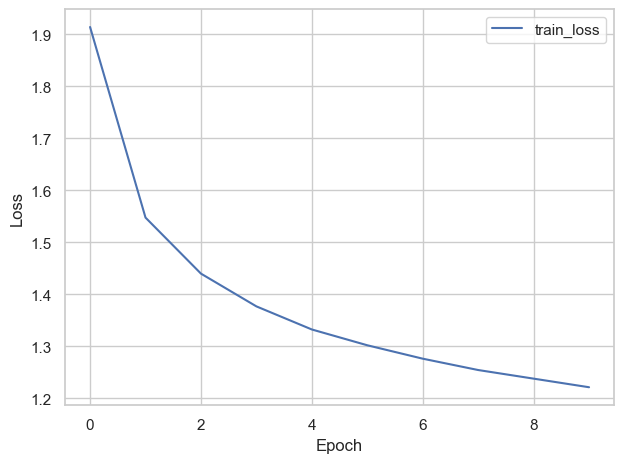

In [66]:
show_history(history)

## 📌 We won't use the raw probabilities directly

Instead of always taking the most likely character (`argmax`), we **sample** from the predicted distribution with a **temperature** `T` that controls creativity:

$$p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

| Temperature | Effect |
|---|---|
| `T < 1` (e.g. 0.2) | **sharp** distribution — safe, predictable text |
| `T = 1` | standard softmax |
| `T > 1` (e.g. 1.5) | **flat** distribution — surprising, chaotic text |

💡 The very same **temperature** knob is used in modern LLMs (ChatGPT, Claude…) to tune how creative the output is.

In [67]:
def sample(logits, temperature=1.0):
    # logits: 1D tensor of raw scores (length = n_chars).
    # Divide by temperature, softmax, then draw one index.
    probs = torch.softmax(logits / temperature, dim=-1)
    return torch.multinomial(probs, num_samples=1).item()

In [68]:
# Sample a single next character for the first training sequence.
gen_model.eval()
with torch.no_grad():
    logits = gen_model(X_ids[0:1].to(device))[0]
print("sampled next char:", repr(indices_char[sample(logits)]))

sampled next char: 'm'


### 💡 The feedback loop (autoregressive generation)

To generate text we form a loop:

1. Start from a **seed** of `SEQ_LEN` characters and encode it as IDs.
2. The model predicts a distribution over the next character.
3. **Sample** one character (with temperature).
4. **Append** it, drop the oldest character (slide the window by 1).
5. Repeat.

Each new character depends on everything generated so far — this is **autoregressive** generation, the same principle behind modern LLMs.

In [69]:
# Generate 500 characters starting from a seed taken from the data.
gen_model.eval()
seed = list(X[10])                 # 40-character seed
generated = list(seed)
seq = list(seed)

with torch.no_grad():
    for _ in range(500):
        ids = torch.tensor([[char_indices[c] for c in seq]], dtype=torch.long).to(device)
        logits = gen_model(ids)[0]
        next_char = indices_char[sample(logits, temperature=0.5)]
        generated.append(next_char)
        seq = generated[-SEQ_LEN:]  # slide the window

#### The model only ever saw single characters — yet it learned real words and phrases 🙂

- It learned to spell plausible English words.
- It respects which letters tend to follow which.
- The output is far from perfect, but the structure of language clearly leaked into the weights.

**How would you make it better?**

- train for more epochs,
- a bigger model (more hidden units / layers),
- a word-level model (given more data),
- train on the whole book series,
- use a modern Transformer (GPT-style) instead of an LSTM.

In [70]:
print("".join(generated))

o lived mr and mrs dursley of number four head the sign the house points and going to get the closer both said ron better the desk harry told her the trees you want to go to the portrait harry thought bird of the stone and the potter well next to our head that they had gotten to the minutes to the light was straight things to the teather to get it off to the malfoy the forest of snape didnt see my really stopped and the door of his face professor mcgonagall said hagrid wouldnt be seen the stone when he was suddenly into his second of 


# Activities ✏️

Try these hands-on. Starter cells are provided — edit and re-run them.

## Activity 1 — Retune the Word2Vec model 🎚️

Rebuild and retrain the Skip-Gram model with **different hyperparameters** and see whether the nearest-neighbour lists improve. Try at least **two** changes:

- a larger `embedding_dim` (e.g. `100`),
- a wider `window_size` (e.g. `4`) when regenerating the training data,
- more `n_epochs`.

Then rerun the similar-word search and compare.

## Activity 2 — Explore temperature 🌡️

Generate text at several temperatures and compare the style. What happens at `T=0.2` versus `T=1.5`?

## Activity 3 — Improve the generator 🏗️

Make the character model stronger. Try at least **one**:

- train for more `epochs`,
- increase `hidden_dim` or `num_layers` in `CharRNN`,
- change `SEQ_LEN` (a longer context) and regenerate the sequences.

Retrain and generate again — did the text get more coherent?

## Activity 4 — Seed the story yourself ✨

So far the model always started from a seed **taken from the book**. Now **you** write the opening — and the model continues your sentence, one character at a time.

**How it works:**

1. You type the **start of a sentence** into `my_seed` (the *seed*).
2. The model reads it and keeps **guessing the next character**, over and over, until it has added `n` more characters.
3. The printed result is **your beginning + the model's continuation**.

**Two rules for the seed:**

- ✏️ Use **lowercase letters and spaces only** — no capitals, digits or punctuation (the model was only trained on `a–z` and space, so it doesn't know other characters).
- 📏 The model needs **exactly 40 characters** of context. The line with `.ljust(SEQ_LEN)` takes care of that automatically: it **pads** a short seed with spaces or **trims** a long one to 40.

Try changing `my_seed` to your own opening and see where the model takes the story!

In [ ]:
my_seed = "harry looked at the castle and then "   # exactly 40 chars, a-z + space